# Inference – model_pose

Same cell order and plots as the original inference notebook. Uses the learned pose output.

Set `GT_BINS_INPUT=False` for ordinary RGB model_pose runs. Set it to `True` only for checkpoints trained with `train_pose_gt_bins.py`; those runs use GT maps and have no trained vision output. Select the checkpoint directory below.


In [12]:
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader

from dataset import SceneTwoPairsDataset
from model_pose import PairImageCylinderModel
from utils import plot_estimated_cylinders_on_images, plot_relative_pose, pose_to_text

# Match the architecture used during training.
IMG_SIZE = 128
PATCH_SIZE = (16, 4)
NUM_BINS = 128
EMBED_DIM = 192
DEPTH = 4
NUM_HEADS = 4
DROPOUT = 0.1

CHECKPOINT_DIR = Path("arrhenius_runs/slurm_long_run_pose_0/checkpoints/")

GT_BINS_INPUT = False  # True only for train_pose_gt_bins.py checkpoints

MODEL_VERSION = "best"  # "best" eller "latest"

CHECKPOINT = CHECKPOINT_DIR / f"{MODEL_VERSION}.pt"

TEST_DATASET = Path("valdataset")
INFERENCE_BATCH_SIZE = 4
VISION_SAMPLE_IDX = 0
INFERENCE_SHOW_TEXT = False
INFERENCE_SHOW_IMAGES = True
OCC_THRESHOLD = 0.2  # Same threshold used in train_v2 inference plots.

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_float32_matmul_precision("high")
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
print("Test dataset:", TEST_DATASET)


Device: cuda
GPU: NVIDIA GeForce RTX 5050 Laptop GPU
Test dataset: valdataset


In [13]:
import torch.nn.functional as F

def gt_bins_to_input(vision, image_size):
    """GT [occupancy, radius, depth, ID] -> three spatial input channels."""
    occupied = (vision[..., 0] > 0.5).float()
    radius = vision[..., 1].float().clamp_min(0)
    depth = vision[..., 2].float().clamp_min(0)
    features = torch.stack([
        occupied,
        torch.log1p(radius) * occupied,
        torch.log1p(depth) * occupied,
    ], dim=1).unsqueeze(2)
    return F.interpolate(features, size=(image_size, image_size), mode="nearest")


def predict_pose_from_gt_bins(model, vision_a, vision_b):
    patch_embed = model.backbone.patch_embed
    image_size = patch_embed.grid_h * patch_embed.patch_h
    input_a = gt_bins_to_input(vision_a, image_size)
    input_b = gt_bins_to_input(vision_b, image_size)
    camera_a, camera_b, patches_a, patches_b = model.backbone(input_a, input_b)
    return model.pose_head(camera_a, camera_b, patches_a, patches_b)


model = PairImageCylinderModel(
    img_size=IMG_SIZE,
    patch_size=PATCH_SIZE,
    in_chans=3,
    embed_dim=EMBED_DIM,
    depth=DEPTH,
    num_heads=NUM_HEADS,
    num_bins=NUM_BINS,
    dropout=DROPOUT,
).to(DEVICE)

checkpoint = torch.load(CHECKPOINT, map_location=DEVICE, weights_only=False)
model.load_state_dict(checkpoint["model_state_dict"], strict=True)
model.eval()
history = checkpoint.get("history")
print(f"Loaded checkpoint: {CHECKPOINT}")
print("Checkpoint epoch:", checkpoint.get("epoch", "unknown"))
print(f"Model parameters: {sum(p.numel() for p in model.parameters()):,}")


Loaded checkpoint: arrhenius_runs/slurm_long_run_pose_0/checkpoints/best.pt
Checkpoint epoch: 170
Model parameters: 4,583,305


In [14]:
# Match train_v2 test dataset construction (no evaluation transform specified).
infer_dataset = SceneTwoPairsDataset(
    root_dir=str(TEST_DATASET),
    return_two_pairs=False,
)
infer_loader = DataLoader(
    infer_dataset,
    batch_size=INFERENCE_BATCH_SIZE,
    shuffle=True,
    num_workers=0,
)
print("Inference dataset size:", len(infer_dataset))


Inference dataset size: 482


In [15]:
batch = next(iter(infer_loader))
img_a, vision_a, img_b, vision_b, pose_ab = batch
img_a, vision_a = img_a.to(DEVICE), vision_a.to(DEVICE)
img_b, vision_b = img_b.to(DEVICE), vision_b.to(DEVICE)
pose_ab = pose_ab.to(DEVICE)

model.eval()
with torch.no_grad():
    if GT_BINS_INPUT:
        pred_pose = predict_pose_from_gt_bins(model, vision_a, vision_b)
        pred_vision = pred_vision_b = None
    else:
        pred_vision, pred_vision_b, pred_pose = model(img_a, img_b)

if not 0 <= VISION_SAMPLE_IDX < len(img_a):
    raise IndexError("VISION_SAMPLE_IDX is outside the inference batch")
if INFERENCE_SHOW_TEXT:
    for i in range(min(4, len(img_a))):
        print(f"Sample {i}")
        print("  GT   pose:", pose_to_text(pose_ab[i].detach().cpu()))
        print("  Pred pose:", pose_to_text(pred_pose[i].detach().cpu()))
        pose_err = torch.abs(pred_pose[i] - pose_ab[i]).detach().cpu()
        print(f"  |err|: tx={pose_err[0]:.3f}, ty={pose_err[1]:.3f}, sin={pose_err[2]:.3f}, cos={pose_err[3]:.3f}")
        print()
if pred_vision is not None:
    print("pred_vision shape:", pred_vision.shape)
print("pred_pose shape:", pred_pose.shape)
print("GT pose:", pose_ab[VISION_SAMPLE_IDX].detach().cpu())
print("Pred pose:", pred_pose[VISION_SAMPLE_IDX].detach().cpu())


pred_vision shape: torch.Size([4, 128, 4])
pred_pose shape: torch.Size([4, 4])
GT pose: tensor([ 0.0188, -0.9998,  0.0000,  1.0000])
Pred pose: tensor([1., 0., 0., 1.])


In [24]:
import inspect
from model import PairImageCylinderModel as OldModel
from model_pose import PairImageCylinderModel as PoseModel

old_path = (
    "arrhenius_runs/slurm_long_run_flipped/"
    "checkpoints/best.pt"
)

old_checkpoint = torch.load(
    old_path, map_location=DEVICE, weights_only=False
)

args = old_checkpoint["args"]
model_kwargs = {
    key: args[key]
    for key in (
        "embed_dim", "depth", "num_heads",
        "num_bins", "dropout"
    )
}
model_kwargs.update(
    img_size=args["img_size"],
    patch_size=tuple(args["patch_size"]),
    in_chans=3,
)

old_model = OldModel(**model_kwargs).to(DEVICE)
pose_model = PoseModel(**model_kwargs).to(DEVICE)

weights = old_checkpoint["model_state_dict"]
old_model.load_state_dict(weights)

result = pose_model.load_state_dict(weights, strict=False)
print("Missing keys:", result.missing_keys)
print("Unexpected keys:", result.unexpected_keys)
# Missing keys ska endast tillhöra det nya posehuvudet.

old_model.eval()
pose_model.eval()

img_a, _, img_b, _, _ = next(iter(infer_loader))
img_a = img_a.to(DEVICE)
img_b = img_b.to(DEVICE)

with torch.no_grad():
    old_a, old_b, _ = old_model(img_a, img_b)
    new_a, new_b, _ = pose_model(img_a, img_b)

for channel, name in enumerate(
    ["occupancy", "radius", "depth", "width"]
):
    difference = max(
        (old_a[..., channel] - new_a[..., channel]).abs().max().item(),
        (old_b[..., channel] - new_b[..., channel]).abs().max().item(),
    )
    print(f"{name:12s} max difference: {difference:.8f}")

print("Old model:", inspect.getfile(OldModel))
print("Pose model:", inspect.getfile(PoseModel))

Missing keys: ['pose_head.net.0.weight', 'pose_head.net.0.bias', 'pose_head.net.1.weight', 'pose_head.net.1.bias', 'pose_head.net.4.weight', 'pose_head.net.4.bias', 'pose_head.net.6.weight', 'pose_head.net.6.bias']
Unexpected keys: []
occupancy    max difference: 0.00000000
radius       max difference: 0.00000000
depth        max difference: 0.00000000
width        max difference: 0.00000000
Old model: /home/johanna/Doktorand/pose_from_cylinders/model.py
Pose model: /home/johanna/Doktorand/pose_from_cylinders/model_pose.py


In [25]:
from losses import (
    vision_loss,
    patch_correspondence_loss,
    relative_depth_structure_loss,
    matched_depth_delta_loss,
)

# Hämta en komplett batch, inklusive facit.
img_a, gt_a, img_b, gt_b, pose_gt = (
    x.to(DEVICE) for x in next(iter(infer_loader))
)


def gradient_check(model, include_pose):
    # Samma slumpsekvens för dropout i båda körningarna.
    torch.manual_seed(123)
    model.train()
    model.zero_grad(set_to_none=True)

    pa, pb, pose, ca, cb = model(
        img_a, img_b, return_corr=True
    )

    vision_kwargs = dict(
        occ_thresh=args["occ_thresh"],
        lambda_occ=args["lambda_occ"],
        lambda_radius=args["lambda_radius"],
        lambda_depth=1.0,
        lambda_width=args["lambda_width"],
    )

    va = vision_loss(pa, gt_a, **vision_kwargs)[0]
    vb = vision_loss(pb, gt_b, **vision_kwargs)[0]

    loss = (
        0.5 * (va + vb)
        + args["lambda_corr"]
        * patch_correspondence_loss(ca, gt_a, cb, gt_b)
        + 0.25 * (
            relative_depth_structure_loss(
                pa, gt_a, args["occ_thresh"]
            )
            + relative_depth_structure_loss(
                pb, gt_b, args["occ_thresh"]
            )
        )
        + args["lambda_depth_delta"]
        * matched_depth_delta_loss(
            pa, gt_a, pb, gt_b, args["occ_thresh"]
        )
    )

    if include_pose:
        # Samma poseförlust som i train_pose, med vikten 0.
        valid = pose_gt[:, :2].norm(dim=-1) > 1e-6
        if valid.any():
            t_loss = (
                1 - (
                    pose[valid, :2]
                    * F.normalize(pose_gt[valid, :2], dim=-1)
                ).sum(-1)
            ).mean()
        else:
            t_loss = pose[:, :2].sum() * 0.0

        r_loss = (
            1 - (
                pose[:, 2:]
                * F.normalize(pose_gt[:, 2:], dim=-1)
            ).sum(-1)
        ).mean()

        loss = loss + 0.0 * (t_loss + r_loss)

    loss.backward()

    grads = {
        name: p.grad.detach().clone()
        for name, p in model.named_parameters()
        if p.grad is not None
        and not name.startswith("pose_head.")
    }
    return loss.item(), grads


old_loss, old_grads = gradient_check(old_model, False)
new_loss, new_grads = gradient_check(pose_model, True)

print("Old loss:", old_loss)
print("New loss:", new_loss)

differences = []
for name in old_grads.keys() & new_grads.keys():
    a, b = old_grads[name], new_grads[name]
    if not torch.isfinite(a).all() or not torch.isfinite(b).all():
        print("NON-FINITE GRADIENT:", name)
    differences.append(((a - b).abs().max().item(), name))

print("\nStörsta gradientskillnader:")
for difference, name in sorted(differences, reverse=True)[:5]:
    print(f"{difference:.8g}  {name}")

print("Olika uppsättningar gradienter:",
      old_grads.keys() ^ new_grads.keys())

old_model.eval()
pose_model.eval()

Old loss: 10.971345901489258
New loss: 10.971345901489258

Största gradientskillnader:
0.00062841177  backbone.view_embed
0.00055760145  backbone.patch_embed.proj.bias
0.00031939149  backbone.blocks.0.self_attn.in_proj_weight
0.00022446364  backbone.blocks.0.self_attn.out_proj.weight
0.00022249669  backbone.patch_embed.proj.weight
Olika uppsättningar gradienter: set()


PairImageCylinderModel(
  (backbone): PairViTBackbone(
    (patch_embed): PatchEmbed(
      (proj): Conv2d(3, 192, kernel_size=(16, 4), stride=(16, 4))
    )
    (pos_drop): Dropout(p=0.1, inplace=False)
    (blocks): ModuleList(
      (0-3): 4 x PairBlock(
        (norm_self): LayerNorm((192,), eps=1e-05, elementwise_affine=True)
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=192, out_features=192, bias=True)
        )
        (norm_cross_q): LayerNorm((192,), eps=1e-05, elementwise_affine=True)
        (norm_cross_kv): LayerNorm((192,), eps=1e-05, elementwise_affine=True)
        (cross_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=192, out_features=192, bias=True)
        )
        (norm_mlp): LayerNorm((192,), eps=1e-05, elementwise_affine=True)
        (mlp): MLP(
          (net): Sequential(
            (0): Linear(in_features=192, out_features=576, bias=True)
            (1

In [27]:
_, old_g1 = gradient_check(old_model, False)
_, old_g2 = gradient_check(old_model, False)

_, new_g1 = gradient_check(pose_model, True)
_, new_g2 = gradient_check(pose_model, True)


def compare_gradients(label, reference, candidate):
    difference_sq = 0.0
    reference_sq = 0.0
    max_difference = 0.0

    for name in reference:
        a = reference[name].double()
        b = candidate[name].double()

        difference_sq += (a - b).square().sum().item()
        reference_sq += a.square().sum().item()
        max_difference = max(
            max_difference,
            (a - b).abs().max().item(),
        )

    relative_l2 = (
        difference_sq / max(reference_sq, 1e-30)
    ) ** 0.5

    print(
        f"{label}: "
        f"max abs={max_difference:.8g}, "
        f"relative L2={relative_l2:.8g}"
    )


compare_gradients("Old mot sig själv", old_g1, old_g2)
compare_gradients("New mot sig själv", new_g1, new_g2)
compare_gradients("Old mot New", old_g1, new_g1)

old_model.eval();
pose_model.eval();

Old mot sig själv: max abs=0.00051385164, relative L2=0.00039750387
New mot sig själv: max abs=0.0005761981, relative L2=0.00042801589
Old mot New: max abs=0.0005671531, relative L2=0.00040532292


In [16]:
from metrics import evaluate_vision

if GT_BINS_INPUT:
    vision_metrics = None
    print("GT-bin run: vision heads were not trained; vision evaluation is skipped.")
else:
    vision_metrics = evaluate_vision(
        model,
        infer_loader,
        DEVICE,
        occ_threshold=OCC_THRESHOLD,
    )



VISION PERFORMANCE

OCCUPANCY, occ_threshold=0.20
------------------------------------------------------------------------------
  Accuracy   Precision    Recall        F1   Recall ±1   Recall ±2
     0.908       0.000     0.000     0.000       0.000       0.000

GEOMETRY
------------------------------------------------------------------------------
                 N       MAE      RMSE      Bias      Corr  Pred std    GT std
Radius       11350     0.138     0.159     0.001     0.007     0.002     0.159
Depth        11350     4.481     5.450     0.020     0.266     0.829     5.611

TOLERANCE ACCURACY
------------------------------------------------------------------------------
Radius         ±0.05 m     ±0.10 m     ±0.20 m
                 0.177       0.365       0.724

Depth           ±0.5 m      ±1.0 m      ±2.0 m      ±5.0 m
                 0.065       0.131       0.262       0.609


In [17]:
@torch.no_grad()
def evaluate_pose(model, loader, device):
    model.eval()
    translation_errors, yaw_errors = [], []
    failures = total = 0
    for batch in loader:
        img_a, gt_a, img_b, gt_b, pose_gt = (
            x.to(device, non_blocking=True) for x in batch
        )
        if GT_BINS_INPUT:
            pose_pred = predict_pose_from_gt_bins(model, gt_a, gt_b)
        else:
            _, _, pose_pred = model(img_a, img_b)
        for pred, gt in zip(pose_pred, pose_gt):
            total += 1
            if (not torch.isfinite(pred).all()
                or torch.linalg.vector_norm(pred[:2]) < 1e-8
                or torch.linalg.vector_norm(gt[:2]) < 1e-8):
                failures += 1
                continue
            t_pred = F.normalize(pred[:2], dim=0)
            t_gt = F.normalize(gt[:2], dim=0)
            cos_t = torch.dot(t_pred, t_gt).clamp(-1.0, 1.0)
            translation_errors.append(torch.rad2deg(torch.acos(cos_t)).item())
            delta = torch.atan2(pred[2], pred[3]) - torch.atan2(gt[2], gt[3])
            yaw_errors.append(torch.rad2deg(torch.atan2(delta.sin(), delta.cos())).abs().item())
    t, yaw = np.asarray(translation_errors), np.asarray(yaw_errors)
    def stat(values, fn):
        return float(fn(values)) if len(values) else float("nan")
    print("CAMERA POSE PERFORMANCE")
    print("=" * 60)
    print(f"\nTest pairs:             {total}")
    print(f"Successful poses:       {len(t)}")
    print(f"Prediction failures:    {failures}")
    print(f"Success rate:           {len(t) / max(total, 1):.3f}")
    for label, values in [("TRANSLATION DIRECTION ERROR", t), ("YAW ERROR", yaw)]:
        print("\n" + label)
        print("-" * 40)
        print(f"Mean:                   {stat(values, np.mean):.2f}°")
        print(f"Median:                 {stat(values, np.median):.2f}°")
        print(f"P90:                    {stat(values, lambda x: np.percentile(x, 90)):.2f}°")
    print("\nACCURACY THRESHOLDS")
    print("-" * 40)
    for threshold in [5, 10, 20, 30]:
        t_acc = stat(t, lambda x: np.mean(x < threshold))
        yaw_acc = stat(yaw, lambda x: np.mean(x < threshold))
        print(f"< {threshold:2d}°: T={100*t_acc:5.1f}% | Yaw={100*yaw_acc:5.1f}%")
    return {
        "translation_errors": t, "yaw_errors": yaw,
        "failures": failures, "total": total,
        "translation_mean": stat(t, np.mean),
        "translation_median": stat(t, np.median),
        "translation_p90": stat(t, lambda x: np.percentile(x, 90)),
        "yaw_mean": stat(yaw, np.mean),
        "yaw_median": stat(yaw, np.median),
        "yaw_p90": stat(yaw, lambda x: np.percentile(x, 90)),
    }

pose_metrics = evaluate_pose(model, infer_loader, DEVICE)


CAMERA POSE PERFORMANCE

Test pairs:             482
Successful poses:       482
Prediction failures:    0
Success rate:           1.000

TRANSLATION DIRECTION ERROR
----------------------------------------
Mean:                   91.37°
Median:                 90.31°
P90:                    151.26°

YAW ERROR
----------------------------------------
Mean:                   3.75°
Median:                 2.19°
P90:                    9.73°

ACCURACY THRESHOLDS
----------------------------------------
<  5°: T=  1.5% | Yaw= 70.7%
< 10°: T=  4.8% | Yaw= 91.3%
< 20°: T=  8.5% | Yaw= 98.5%
< 30°: T= 11.6% | Yaw= 99.8%


## 1. Input image pair


In [18]:
# Plots are controlled by INFERENCE_SHOW_IMAGES in the following cells.


## 2. Vision prediction

Compare the predicted `(occupancy, radius, depth)` against the ground truth for image A.


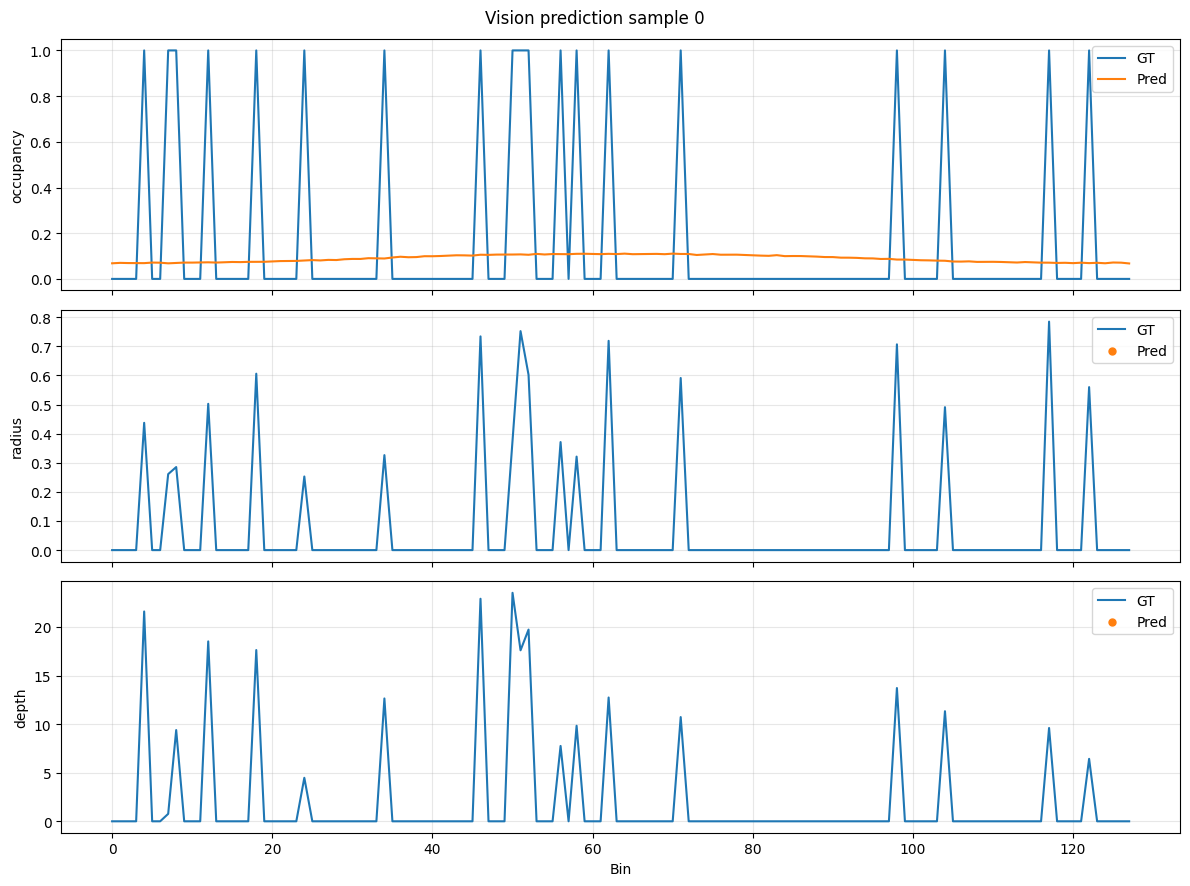

In [19]:
sample_idx = VISION_SAMPLE_IDX
bins = np.arange(vision_a.shape[1])
PLOT_OCC_THRESHOLD = 0.2
if INFERENCE_SHOW_IMAGES and not GT_BINS_INPUT:
    fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
    names = ["occupancy", "radius", "depth"]
    pr_occ = pred_vision[sample_idx, :, 0].detach().cpu().numpy()
    for j, ax in enumerate(axes):
        gt = vision_a[sample_idx, :, j].detach().cpu().numpy()
        pr = pred_vision[sample_idx, :, j].detach().cpu().numpy()
        ax.plot(bins, gt, label="GT", color="tab:blue")
        if j == 0:
            ax.plot(bins, pr, label="Pred", color="tab:orange")
        else:
            pr_mask = pr_occ > PLOT_OCC_THRESHOLD
            ax.scatter(bins[pr_mask], pr[pr_mask], label="Pred", color="tab:orange", s=25)
        ax.set_ylabel(names[j])
        ax.grid(True, alpha=0.3)
        ax.legend()
    axes[-1].set_xlabel("Bin")
    fig.suptitle(f"Vision prediction sample {sample_idx}")
    plt.tight_layout()
    plt.show()


## 3. Estimated cylinders and input images


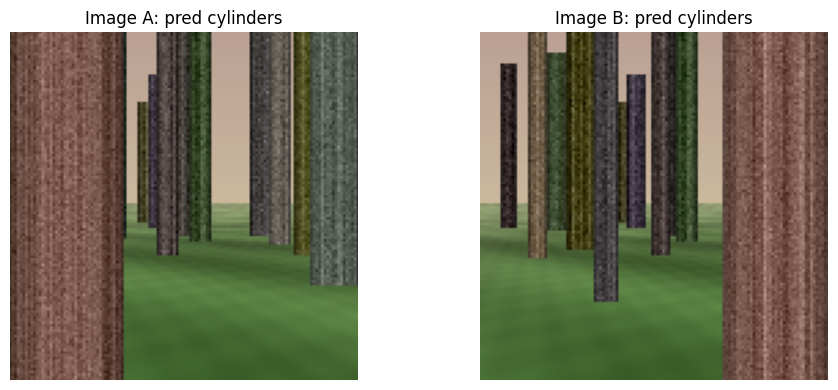

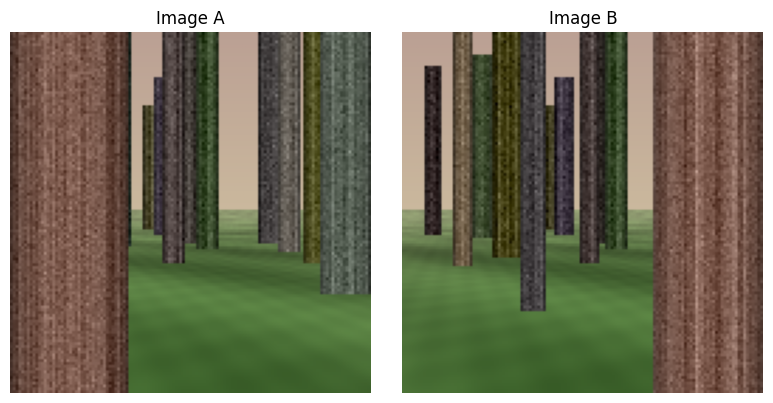

In [20]:
if INFERENCE_SHOW_IMAGES:
    if not GT_BINS_INPUT:
        fig_cyl, axes_cyl = plot_estimated_cylinders_on_images(
            [img_a[VISION_SAMPLE_IDX], img_b[VISION_SAMPLE_IDX]],
            [pred_vision[VISION_SAMPLE_IDX], pred_vision_b[VISION_SAMPLE_IDX]],
            titles=["Image A: pred cylinders", "Image B: pred cylinders"],
            occ_threshold=PLOT_OCC_THRESHOLD,
            flip_x=True,
        )
        plt.show()
    fig, axes = plt.subplots(1, 2, figsize=(8, 4))
    axes[0].imshow(img_a[VISION_SAMPLE_IDX].cpu().permute(1, 2, 0))
    axes[0].set_title("Image A")
    axes[0].axis("off")
    axes[1].imshow(img_b[VISION_SAMPLE_IDX].cpu().permute(1, 2, 0))
    axes[1].set_title("Image B")
    axes[1].axis("off")
    plt.tight_layout()
    plt.show()


## 4. Relative pose


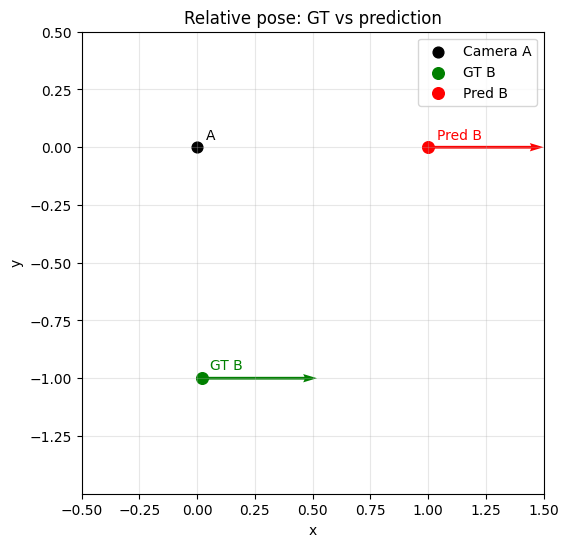

In [21]:
gt_pose = pose_ab[VISION_SAMPLE_IDX].detach().cpu()
pred_pose_sample = pred_pose[VISION_SAMPLE_IDX].detach().cpu()
if INFERENCE_SHOW_TEXT:
    print("GT :", pose_to_text(gt_pose))
    print("Pred:", pose_to_text(pred_pose_sample))
if INFERENCE_SHOW_IMAGES:
    plot_relative_pose(pose_ab[VISION_SAMPLE_IDX], pred_pose[VISION_SAMPLE_IDX])


## 5. Training history (optional)

Plot epoch-aligned loss curves stored in the selected checkpoint.


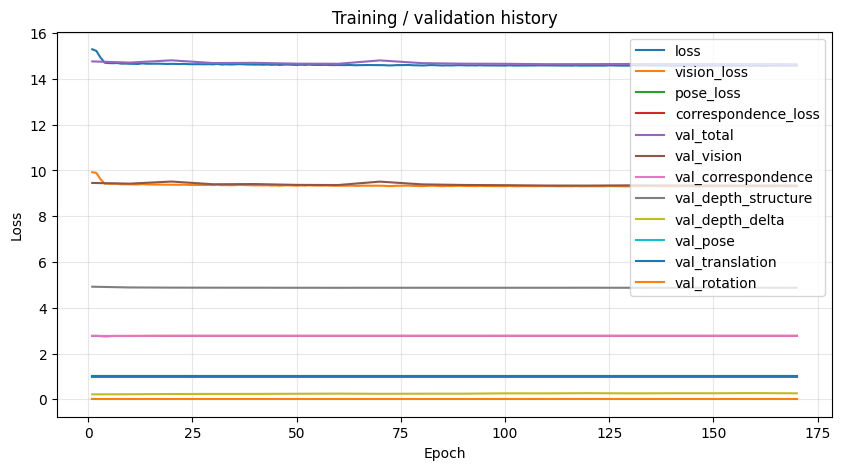

In [22]:
# train_v2 stores history as a dictionary of epoch-aligned metrics.
if isinstance(history, dict):
    epochs = history.get("epoch", [])
    val_epochs = history.get("val_epoch", [])
    train_keys = ["loss", "vision_loss", "pose_loss", "correspondence_loss", "pose", "translation", "rotation"]
    val_keys = ["val_total", "val_vision", "val_correspondence", "val_depth_structure", "val_depth_delta", "val_pose", "val_translation", "val_rotation"]
    plt.figure(figsize=(10, 5))
    plotted = False
    for keys, xs, prefix in [(train_keys, epochs, "train"), (val_keys, val_epochs, "val")]:
        for key in keys:
            ys = history.get(key, [])
            if len(xs) and len(ys) == len(xs):
                plt.plot(xs, ys, label=key)
                plotted = True
    if plotted:
        plt.xlabel("Epoch")
        plt.ylabel("Loss")
        plt.title("Training / validation history")
        plt.grid(True, alpha=0.3)
        plt.legend()
        plt.show()
    else:
        plt.close()
        print("History present, but no matching epoch-aligned loss curves.")
else:
    print("No training history stored in the selected checkpoint.")
